# Downstream results

Every evaluation record in `results/records` (ingested into `results/experiments.sqlite`), one table per task.

* **score**: test metric with bootstrap 95% CI, for the head picked on **validation** (`picked on = test!` means the task had no validation score).
* **Δ random**: test minus the random-init encoder (`random_small`) on the same task — the floor every pretrained model must beat.
* **pretrain overlap**: share of the task's volumes that were in the (unlabelled) pretraining pool.

Re-run from the top to pick up new records. Helpers live in `brain/downstream/results_view.py`.

In [8]:
import sys
from pathlib import Path

# make the repo importable whatever the kernel's working directory or environment
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "brain" / "__init__.py").exists()),
            Path("/home/roku/brain-model"))
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from brain.downstream import results_view as rv

pd.set_option("display.max_colwidth", 60)
rep = rv.load(ingest=True)          # folds new record files into the database first
MODELS = None                       # e.g. ["random_small (final)", "cls_s42 @15k", "cls_reg4_s42 @15k"]
if MODELS:
    rep = rep[rep.model.isin(MODELS)]
display(rep.groupby("model").task.nunique().rename("tasks scored").to_frame())

,tasks scored
model,
cls_reg4_s42 @15k,13
cls_s42 @15k,14
mae3d_base_s42 @920,14
mae3d_small_v2_s42 @30k,25
mt_v3init_s42 @15k,22
none_s42 @15k,13
random_small (final),28
random_small_tiled (final),10
v2_cls_s42 @16k,13


## Model subset

`label-seen` (per-task tables) marks tasks a label-trained model (multitask) has seen: `labels` = that task's own labels; `task` = the same target from other cohorts. `rv.overview(rep, hide_seen="labels")` blanks the former, `hide_seen="task"` both.


In [9]:
# Which models to show: glob patterns on the model labels (all names: sorted(rep_all.model.unique())).
# keep=None shows every model not dropped; random-init baselines stay unless dropped explicitly.
KEEP = None                      # e.g. ["v3_cls_s42 @18k", "mae3d_small_v2*", "mt_*"]
DROP = [
    "cls_reg4_s42*", "cls_s42 @15k", "none_s42*",       # prefix ablation arms (v3 chose cls)
    "v2_cls_s42*", "v3_cls_s42 @16k",                    # superseded checkpoints
    "v3_cls_s42_tiled*", "v3_cls_s42_b4*", "random_small_tiled*",   # context / early-layer diagnostics
    "mae3d_base_s42*",                                   # MAE v1 (stopped at 920)
]
rep_all = rep
rep = rv.select(rep_all, keep=KEEP, drop=DROP)
print(sorted(rep.model.unique()))

['mae3d_small_v2_s42 @30k', 'mt_v3init_s42 @15k', 'random_small (final)', 'v3_cls_s42 @18k']


## Overview: test scores

In [10]:
rv.overview(rep)

## Overview: gain over random-init

In [7]:
rv.overview(rep, delta=True)

## Per task

### classification

#### `abide_asd`

,model,auc,Δ random,head,picked on,pretrain overlap
0,none_s42 @15k,"0.609 [0.524, 0.695]",+0.028,tok_conv,val,100%
1,cls_reg4_s42 @15k,"0.599 [0.512, 0.683]",+0.019,tok_conv,val,100%
2,random_small (final),"0.581 [0.491, 0.665]",+0.000,tok_conv,val,100%
3,cls_s42 @15k,"0.567 [0.477, 0.651]",-0.014,tok_conv,val,100%
4,v2_cls_s42 @16k,"0.560 [0.472, 0.643]",-0.021,tok_conv,val,100%
5,v3_cls_s42 @16k,"0.558 [0.461, 0.650]",-0.022,pca_global_logreg,val,100%


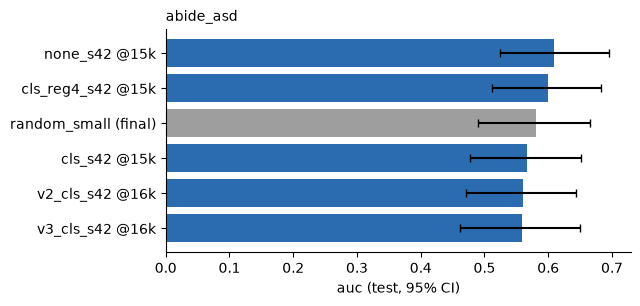

#### `cq500`

,model,auc_ovr_macro,Δ random,head,picked on,pretrain overlap
0,none_s42 @15k,"0.874 [0.820, 0.919]",+0.083,tok_conv,val,0%
1,v2_cls_s42 @16k,"0.866 [0.817, 0.906]",+0.075,cls_logreg,val,0%
2,cls_s42 @15k,"0.863 [0.812, 0.907]",+0.072,cls_logreg,val,0%
3,v3_cls_s42 @16k,"0.831 [0.763, 0.887]",+0.039,tok_conv,val,0%
4,random_small (final),"0.791 [0.715, 0.857]",+0.000,tok_conv,val,0%
5,cls_reg4_s42 @15k,"0.754 [0.689, 0.820]",-0.037,reg_logreg,val,0%


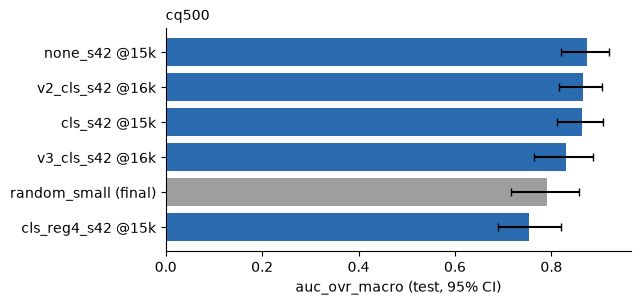

#### `msd`

,model,auc,Δ random,head,picked on,pretrain overlap
0,v3_cls_s42 @16k,"0.956 [0.898, 0.992]",+0.132,tok_conv,val,0%
1,cls_reg4_s42 @15k,"0.879 [0.794, 0.951]",+0.055,tok_conv,val,0%
2,cls_s42 @15k,"0.878 [0.786, 0.952]",+0.054,tok_conv,val,0%
3,v2_cls_s42 @16k,"0.858 [0.768, 0.941]",+0.034,tok_conv,val,0%
4,random_small (final),"0.824 [0.708, 0.923]",+0.000,plane_logreg,val,0%
5,none_s42 @15k,"0.785 [0.655, 0.892]",-0.039,plane_logreg,val,0%


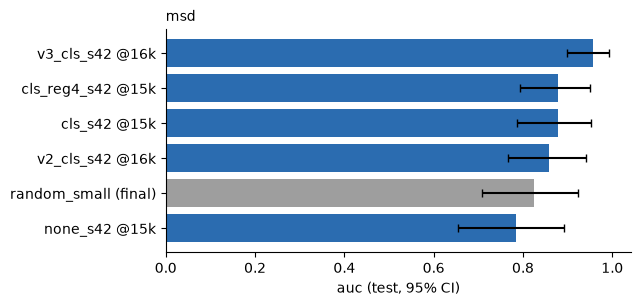

#### `oasis1_cdr`

,model,auc,Δ random,head,picked on,pretrain overlap
0,cls_s42 @15k,"0.749 [0.580, 0.888]",+0.067,grid_logreg,val,100%
1,none_s42 @15k,"0.730 [0.551, 0.890]",+0.048,grid_logreg,val,100%
2,v3_cls_s42 @16k,"0.719 [0.547, 0.874]",+0.037,plane_logreg,val,100%
3,random_small (final),"0.682 [0.497, 0.840]",+0.000,pca_global_logreg,val,100%
4,v2_cls_s42 @16k,"0.652 [0.467, 0.836]",-0.029,grid_logreg,val,100%
5,cls_reg4_s42 @15k,"0.588 [0.408, 0.772]",-0.094,grid_logreg,val,100%


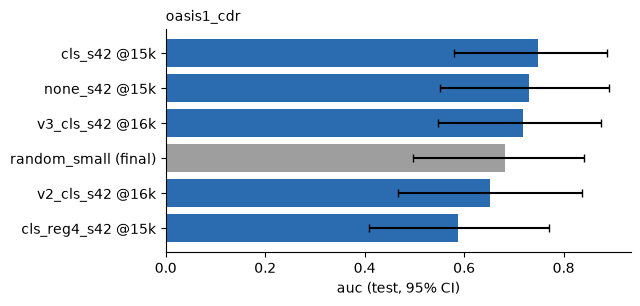

#### `oasis2_cdr`

,model,auc,Δ random,head,picked on,pretrain overlap
0,random_small (final),"0.712 [0.628, 0.790]",+0.000,pca_global_logreg,val,40%
1,none_s42 @15k,"0.712 [0.619, 0.796]",-0.000,pca_global_logreg,val,40%
2,v3_cls_s42 @16k,"0.678 [0.584, 0.766]",-0.034,grid_logreg,val,40%
3,cls_s42 @15k,"0.617 [0.525, 0.706]",-0.096,grid_logreg,val,40%
4,cls_reg4_s42 @15k,"0.612 [0.515, 0.704]",-0.101,pca_global_logreg,val,40%
5,v2_cls_s42 @16k,"0.557 [0.461, 0.659]",-0.155,pca_global_logreg,val,40%


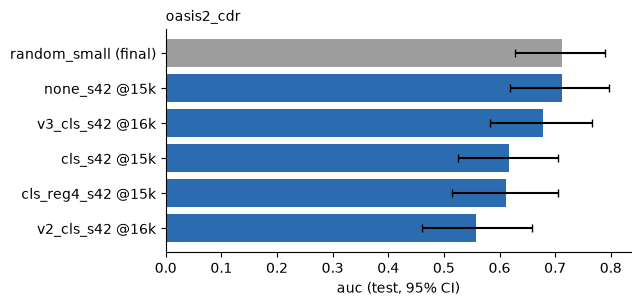

#### `oasis2_conversion`

,model,auc,Δ random,head,picked on,pretrain overlap
0,none_s42 @15k,"0.635 [0.301, 0.974]",+0.191,plane_logreg,val,100%
1,cls_s42 @15k,"0.617 [0.216, 0.959]",+0.174,grid_logreg,val,100%
2,random_small (final),"0.443 [0.160, 0.741]",+0.000,tok_conv,val,100%
3,v3_cls_s42 @16k,"0.235 [0.000, 0.469]",-0.209,tok_conv,val,100%
4,cls_reg4_s42 @15k,"0.191 [0.000, 0.514]",-0.252,tok_conv,val,100%
5,v2_cls_s42 @16k,"0.174 [0.000, 0.453]",-0.270,tok_conv,val,100%


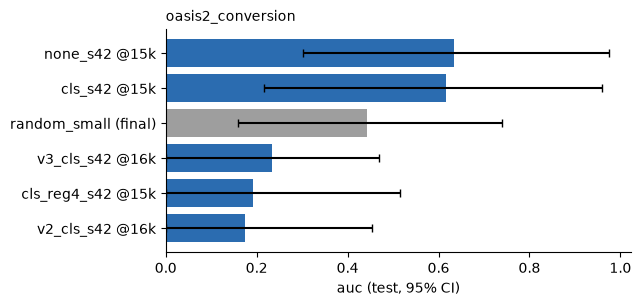

### regression

#### `id1000_age`

,model,r2,Δ random,head,picked on,pretrain overlap
0,random_small (final),"0.180 [0.065, 0.269]",+0.000,plane_ridge,val,100%
1,v3_cls_s42 @16k,"0.127 [0.002, 0.223]",-0.053,tok_conv,val,100%
2,v2_cls_s42 @16k,"0.042 [-0.065, 0.118]",-0.138,tok_conv,val,100%
3,cls_reg4_s42 @15k,"0.001 [-0.168, 0.138]",-0.179,clsreg_ridge,val,100%
4,none_s42 @15k,"-0.027 [-0.161, 0.062]",-0.207,tok_conv,val,100%
5,cls_s42 @15k,"-0.036 [-0.231, 0.130]",-0.216,cls_ridge,val,100%


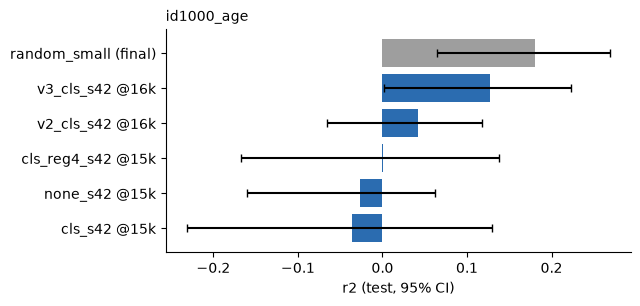

#### `ixi_age`

,model,r2,Δ random,head,picked on,pretrain overlap
0,v3_cls_s42 @16k,"0.844 [0.777, 0.888]",+0.162,tok_conv,val,100%
1,cls_reg4_s42 @15k,"0.808 [0.726, 0.864]",+0.126,tok_conv,val,100%
2,v2_cls_s42 @16k,"0.801 [0.708, 0.859]",+0.119,tok_conv,val,100%
3,cls_s42 @15k,"0.788 [0.691, 0.848]",+0.106,tok_conv,val,100%
4,none_s42 @15k,"0.762 [0.672, 0.820]",+0.080,grid_ridge,val,100%
5,random_small (final),"0.682 [0.520, 0.779]",+0.000,tok_conv,val,100%


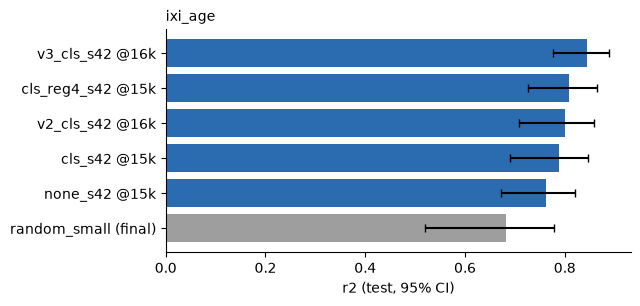

#### `ms3seg_age`

,model,r2,Δ random,head,picked on,pretrain overlap
0,random_small (final),"0.366 [0.177, 0.473]",+0.000,plane_ridge,val,0%
1,v3_cls_s42 @16k,"0.319 [0.139, 0.425]",-0.046,grid_ridge,val,0%


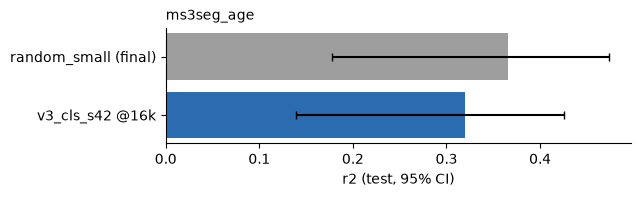

#### `oasis1_age`

,model,r2,Δ random,head,picked on,pretrain overlap
0,none_s42 @15k,"0.920 [0.887, 0.944]",+0.104,tok_conv,val,95%
1,v3_cls_s42 @16k,"0.883 [0.836, 0.915]",+0.067,tok_conv,val,95%
2,cls_s42 @15k,"0.882 [0.839, 0.915]",+0.067,tok_conv,val,95%
3,v2_cls_s42 @16k,"0.873 [0.821, 0.908]",+0.057,tok_conv,val,95%
4,cls_reg4_s42 @15k,"0.860 [0.800, 0.903]",+0.044,tok_conv,val,95%
5,random_small (final),"0.816 [0.723, 0.886]",+0.000,tok_conv,val,95%


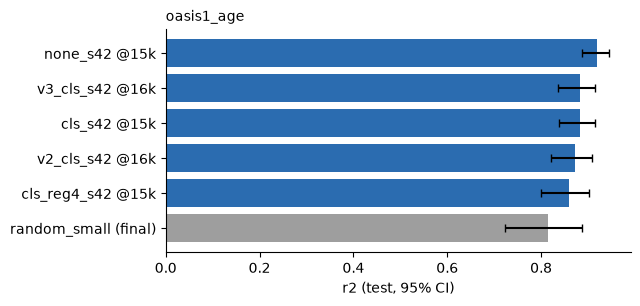

#### `piop1_age`

,model,r2,Δ random,head,picked on,pretrain overlap
0,random_small (final),"0.060 [-0.267, 0.194]",+0.000,grid_ridge,val,100%
1,v2_cls_s42 @16k,"0.009 [-0.371, 0.184]",-0.050,grid_ridge,val,100%
2,cls_s42 @15k,"-0.029 [-0.489, 0.193]",-0.089,grid_ridge,val,100%
3,v3_cls_s42 @16k,"-0.032 [-0.496, 0.170]",-0.091,cls_ridge,val,100%
4,none_s42 @15k,"-0.034 [-0.475, 0.152]",-0.094,grid_ridge,val,100%
5,cls_reg4_s42 @15k,"-0.072 [-0.686, 0.271]",-0.132,grid_ridge,val,100%


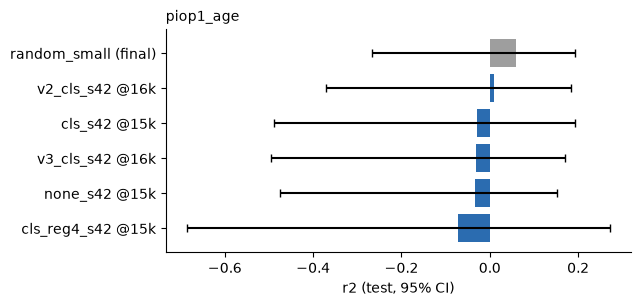

#### `piop2_age`

,model,r2,Δ random,head,picked on,pretrain overlap
0,v3_cls_s42 @16k,"-0.068 [-0.511, 0.142]",+0.399,grid_ridge,val,100%
1,cls_s42 @15k,"-0.130 [-0.576, 0.097]",+0.337,cls_ridge,val,100%
2,cls_reg4_s42 @15k,"-0.133 [-0.590, 0.013]",+0.334,cls_ridge,val,100%
3,v2_cls_s42 @16k,"-0.182 [-0.590, -0.002]",+0.285,grid_ridge,val,100%
4,none_s42 @15k,"-0.332 [-0.865, -0.081]",+0.134,grid_ridge,val,100%
5,random_small (final),"-0.467 [-1.265, 0.003]",+0.000,plane_ridge,val,100%


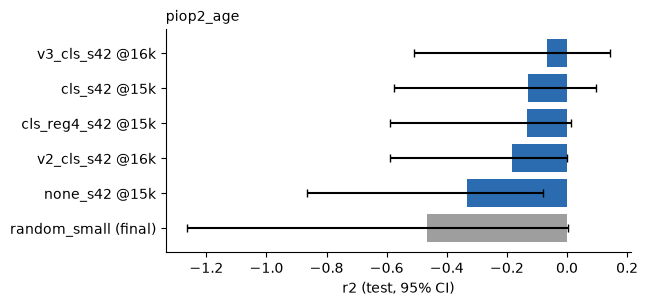

#### `pixar_age`

,model,r2,Δ random,head,picked on,pretrain overlap
0,cls_reg4_s42 @15k,"0.914 [0.856, 0.953]",+0.018,tok_conv,val,100%
1,random_small (final),"0.897 [0.801, 0.941]",+0.000,tok_conv,val,100%
2,cls_s42 @15k,"0.827 [0.605, 0.910]",-0.070,grid_ridge,val,100%
3,none_s42 @15k,"0.818 [0.568, 0.925]",-0.079,tok_conv,val,100%
4,v2_cls_s42 @16k,"0.812 [0.499, 0.918]",-0.085,grid_ridge,val,100%
5,v3_cls_s42 @16k,"0.805 [0.567, 0.923]",-0.091,tok_conv,val,100%


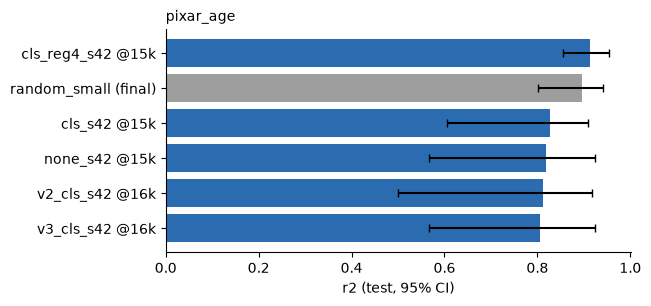

#### `valdo_epvs`

,model,r2,Δ random,head,picked on,pretrain overlap
0,v3_cls_s42 @16k,"0.300 [-0.030, 0.520]",+0.067,cls_ridge,val,0%
1,random_small (final),"0.233 [-0.041, 0.399]",+0.000,plane_ridge,val,0%


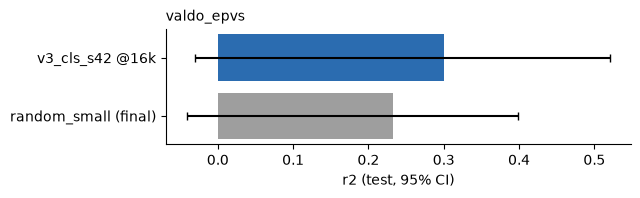

### segmentation

#### `atlas`

,model,dice_macro,Δ random,head,picked on,pretrain overlap
0,random_small (final),"0.310 [0.272, 0.350]",+0.000,tok_unet3d,val,0%
1,cls_s42 @15k,"0.274 [0.239, 0.310]",-0.036,tok_unet3d,val,0%


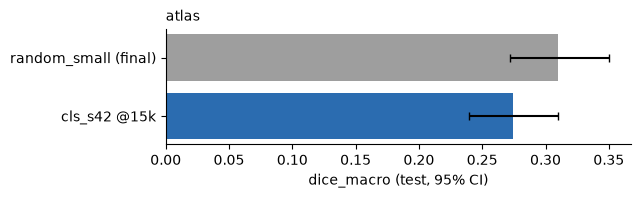

#### `brats2023_gli`

,model,dice_macro,Δ random,head,picked on,pretrain overlap
0,random_small (final),"0.839 [0.820, 0.853]",+0.000,tok_unet3d,val,88%


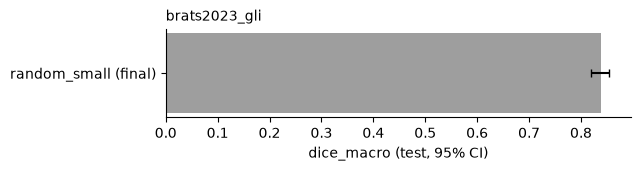

#### `brats2023_men`

,model,dice_macro,Δ random,head,picked on,pretrain overlap
0,random_small (final),"0.705 [0.663, 0.747]",+0.000,tok_unet3d,val,94%


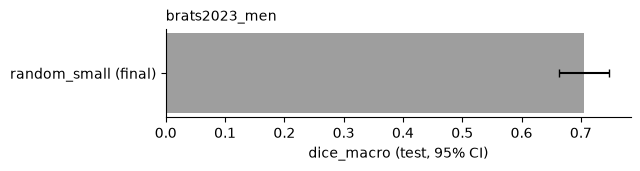

#### `brats2023_ped`

,model,dice_macro,Δ random,head,picked on,pretrain overlap
0,random_small (final),"0.585 [0.474, 0.684]",+0.000,tok_unet3d,val,100%


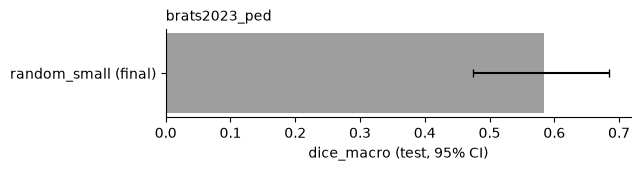

#### `brats2024_gli`

,model,dice_macro,Δ random,head,picked on,pretrain overlap
0,random_small (final),"0.514 [0.520, 0.559]",+0.000,tok_unet3d,val,45%


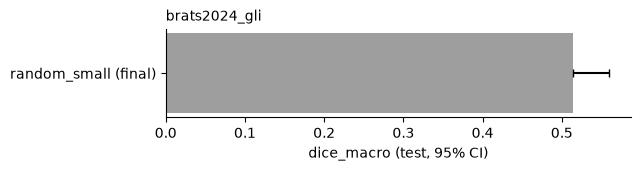

#### `isles22`

,model,dice_macro,Δ random,head,picked on,pretrain overlap
0,random_small (final),"0.543 [0.462, 0.625]",+0.000,tok_unet3d,val,0%


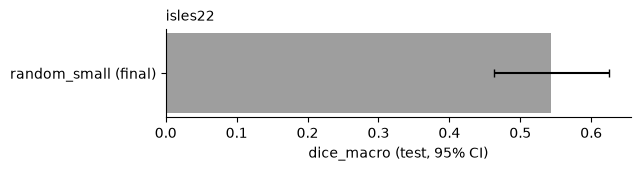

#### `seg_cq500`

,model,dice_macro,Δ random,head,picked on,pretrain overlap
0,v3_cls_s42 @16k,"0.278 [0.124, 0.446]",+0.095,tok_unet3d,val,0%
1,cls_s42 @15k,"0.253 [0.092, 0.435]",+0.069,tok_unet3d,val,0%
2,none_s42 @15k,"0.223 [0.069, 0.409]",+0.040,tok_unet3d,val,0%
3,random_small (final),"0.184 [0.051, 0.354]",+0.000,tok_unet3d,val,0%
4,cls_reg4_s42 @15k,"0.175 [0.050, 0.345]",-0.008,tok_unet3d,val,0%
5,v2_cls_s42 @16k,"0.172 [0.050, 0.320]",-0.012,tok_unet3d,val,0%


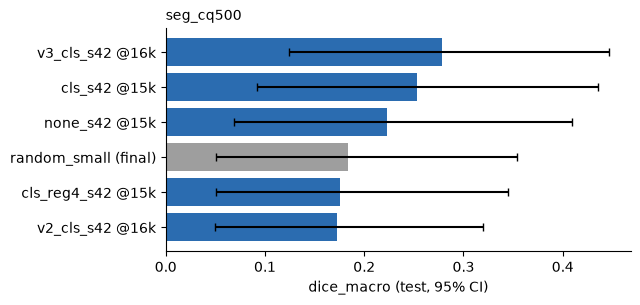

In [8]:
for group in rv.GROUP_ORDER:
    tasks = sorted(rep.loc[rep.group == group, "task"].unique())
    if not tasks:
        continue
    display(Markdown(f"### {group}"))
    for task in tasks:
        display(Markdown(f"#### `{task}`"))
        display(rv.task_table(rep, task))
        rv.plot_task(rep, task)
        plt.show()

## Drill-down: every head on one task

Check that the validation-picked head is not a fluke (val vs test per head).

In [10]:
rv.all_heads("cq500")

,model,task,head,view,metric,val,test,ci_lo,ci_hi,n_test,pretrain_overlap,finished_utc
0,cls_s42 @15k,cq500,cls_logreg,cls,auc_ovr_macro,0.827618,0.862777,0.811837,0.907244,70,0.0,2026-10-19T01:59:52+00:00
1,cls_s42 @15k,cq500,tok_conv,tokens,auc_ovr_macro,0.809566,0.810736,0.736596,0.871768,70,0.0,2026-10-19T01:59:52+00:00
2,cls_s42 @15k,cq500,plane_logreg,plane,auc_ovr_macro,0.768685,0.769720,0.704055,0.830803,70,0.0,2026-10-19T01:59:52+00:00
3,cls_s42 @15k,cq500,pca_global_logreg,global,auc_ovr_macro,0.740577,0.656567,0.527889,0.774599,70,0.0,2026-10-19T01:59:52+00:00
4,cls_s42 @15k,cq500,grid_logreg,grid,auc_ovr_macro,0.697814,0.764150,0.697344,0.816178,70,0.0,2026-10-19T01:59:52+00:00
5,random_small (final),cq500,tok_conv,tokens,auc_ovr_macro,0.783753,0.791044,0.715497,0.857477,70,0.0,2026-10-18T17:27:20+00:00
6,random_small (final),cq500,grid_logreg,grid,auc_ovr_macro,0.683114,0.746497,0.677732,0.805859,70,0.0,2026-10-18T17:27:20+00:00
7,random_small (final),cq500,plane_logreg,plane,auc_ovr_macro,0.671578,0.684772,0.606460,0.758997,70,0.0,2026-10-18T17:27:20+00:00
8,random_small (final),cq500,pca_global_logreg,global,auc_ovr_macro,0.593801,0.629000,0.529561,0.719476,70,0.0,2026-10-18T17:27:20+00:00


## Token probes (lesion / fingerprint / location)

In [ ]:
rv.probes()